# Asistente RAG sobre literatura latinoamericana

**Trabajo Práctico 1 — Aprendizaje Automático II (PLN y Retrieval-Augmented Generation)**
ISTEA · Prof. César Martínez

## 1. Título e integrantes

| Rol | Integrante | Responsabilidad |
|---|---|---|
| 1 | Rodolfo Javier Berrone | Corpus: descarga, limpieza y estadísticas |
| 2 | Paola Lucía Pierolivo Fernández | Chunking A y B, y su comparación |
| 3 | Mauricio Chocholacek | Embeddings, índice FAISS y función `buscar()` |
| 4 | Andrea Romeo | Set de 10 preguntas y evaluación `hit@k` |
| 5 | Verónica Andrea González | LLM con y sin RAG, y calificación C/P/I/A |
| 6 | Daiana Marilyn Ruiz Díaz | Notebook final e informe |

**Fecha de entrega:** viernes 09/10/2026

**Cómo correrlo:** todo lo necesario está en el repo (https://github.com/javi2481/rag-literatura-latinoamericana): el corpus, las respuestas del LLM y el código. No hace falta Google Drive ni ninguna API key.
1. En Colab: abrir el notebook y *Ejecutar todo*; si no encuentra la carpeta `datos/`, clona el repo solo. En local: `git clone https://github.com/javi2481/rag-literatura-latinoamericana.git`, `pip install -r requirements.txt` y *Reiniciar y ejecutar todo*.
2. Por defecto (`GENERAR = False`) usa las respuestas del LLM guardadas en `resultados/respuestas_llm.json` y corre sin GPU. Con `GENERAR = True` carga `Qwen/Qwen2.5-1.5B-Instruct` y vuelve a generar las 20 respuestas; para eso conviene una GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*).

## Instalación e importación de librerías

In [1]:
# Dependencias (las mismas de requirements.txt en la raíz del repo)
%pip install -q wikipedia sentence-transformers==6.3.0 faiss-cpu==1.16.0 transformers==5.22.2 accelerate

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import time
import json
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wikipedia

# False: usa las respuestas del LLM guardadas en resultados/respuestas_llm.json (corre sin GPU).
# True: carga Qwen2.5-1.5B-Instruct y vuelve a generar las respuestas (conviene GPU T4).
GENERAR = False

# Raíz del repo: el notebook vive en notebooks/, así que subimos un nivel
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (RAIZ / "datos").is_dir():
    # Fuera del repo (por ejemplo, en Colab): usamos una copia clonada del repo, y la clonamos si todavía no existe
    RAIZ = Path.cwd() / "rag-literatura-latinoamericana"
    if not (RAIZ / "datos").is_dir():
        clon = subprocess.run(["git", "clone", "-q", "https://github.com/javi2481/rag-literatura-latinoamericana.git", str(RAIZ)],
                              capture_output=True, text=True)
        assert clon.returncode == 0, f"No se pudo clonar el repo:\n{clon.stderr}"
DATOS = RAIZ / "datos"
RESULTADOS = RAIZ / "resultados"
SALIDA = RAIZ / "runs" / "entrega"   # acá se guardan las tablas al final (la carpeta está en .gitignore)

pd.set_option("display.max_colwidth", None)

**Mapa de progreso.** Al inicio de cada fase mostramos en qué etapa del trabajo estamos: verde, terminada; amarillo, la actual; gris, pendiente. Debajo de cada etapa terminada va su resultado principal.

In [3]:
ETAPAS = ["Corpus", "Chunking A/B", "Índice FAISS", "Evaluación hit@k", "Con RAG vs. sin RAG"]
resultados_etapas = {}   # cada fase agrega acá su resultado principal

# Texto de cada caja, partido en dos líneas para que entre cómodo
ETIQUETAS = {"Corpus": "Corpus", "Chunking A/B": "Chunking\nA / B", "Índice FAISS": "Índice\nFAISS",
             "Evaluación hit@k": "Evaluación\nhit@k", "Con RAG vs. sin RAG": "Con RAG vs.\nsin RAG"}

# Función para dibujar el mapa de progreso, marcando la etapa actual
def mostrar_progreso(etapa_actual):
    # Posición de la etapa actual; si no está en la lista ("Fin"), todas quedan terminadas
    actual = ETAPAS.index(etapa_actual) if etapa_actual in ETAPAS else len(ETAPAS)

    fig, ax = plt.subplots(figsize=(15, 2.2))
    for i, etapa in enumerate(ETAPAS):
        # Verde: terminada | amarillo: actual | gris: pendiente
        if i < actual:
            color, texto = "#b7e1b5", ETIQUETAS[etapa] + " ✓"
        elif i == actual:
            color, texto = "#ffe08a", ETIQUETAS[etapa]
        else:
            color, texto = "#e6e6e6", ETIQUETAS[etapa]

        x = i * 3   # cada caja ocupa 2.4 de ancho y deja 0.6 para la flecha
        ax.add_patch(plt.Rectangle((x, 0), 2.4, 1, facecolor=color, edgecolor="gray"))
        ax.text(x + 1.2, 0.5, texto, ha="center", va="center", fontsize=11, weight="bold")
        ax.text(x + 1.2, -0.35, resultados_etapas.get(etapa, ""), ha="center", fontsize=9, color="dimgray")
        if i < len(ETAPAS) - 1:
            ax.annotate("", xy=(x + 3, 0.5), xytext=(x + 2.4, 0.5), arrowprops=dict(arrowstyle="->"))

    ax.set_xlim(-0.2, len(ETAPAS) * 3)
    ax.set_ylim(-0.7, 1.2)
    ax.axis("off")
    plt.show()

## 2. Introducción

Los modelos de lenguaje responden con fluidez sobre casi cualquier tema, pero cuando no tienen el dato correcto suelen inventarlo (alucinaciones). RAG (*Retrieval-Augmented Generation*) busca reducir ese problema: antes de responder, el sistema busca en un corpus propio los fragmentos relacionados con la pregunta y se los pasa al modelo, con la instrucción de responder solo con esa información.

En este trabajo armamos y evaluamos un sistema RAG en español. Queríamos ver dos cosas: cuánto influye la forma de partir los textos (*chunking*) en la calidad de la búsqueda, y qué cambia en las respuestas de un LLM cuando tiene contexto (con RAG) y cuando no lo tiene (sin RAG).

El trabajo tiene cuatro etapas: corpus y chunking, embeddings e índice FAISS, evaluación del buscador con `hit@k`, y generación de respuestas con un LLM open-source, que calificamos a mano.

## 3. Corpus y objetivos

**Corpus.** Seis artículos de Wikipedia en español, uno por autor de la literatura latinoamericana: Jorge Luis Borges, Julio Cortázar, Gabriel García Márquez, Mario Vargas Llosa, Ernesto Sabato y Adolfo Bioy Casares. Después de la limpieza suman unos 300.000 caracteres, cinco veces el mínimo de 60.000 que pide la consigna.

**Por qué este corpus.** Los seis artículos son biografías con una estructura muy parecida: nacimiento, obras, premios, vida personal. Eso hace que la búsqueda no sea trivial: para responder "¿dónde nació Cortázar?" el buscador tiene que distinguir entre seis textos que hablan de nacimientos, ciudades y fechas.

**Qué preguntas esperamos responder.** Preguntas con un dato concreto sobre cada autor: lugar y año de nacimiento, obras, premios y colaboraciones con otros autores.

**Objetivos:**
- Armar y limpiar un corpus en español.
- Comparar dos estrategias de chunking: tamaño fijo con overlap (A) y por párrafos (B).
- Indexar los chunks con embeddings y FAISS, y medir la búsqueda con `hit@1`, `hit@3` y `hit@5`.
- Comparar las respuestas de un LLM con y sin RAG, calificándolas como Correcta, Parcial, Incorrecta o Alucinación.

## 4. Descarga y limpieza del corpus

Para armar el corpus usamos la librería `wikipedia`, igual que en el notebook de clase `PLN_RAG_pipeline`, con el idioma en español. En Wikipedia el artículo de Sabato figura sin tilde ("Ernesto Sabato").

Descargar en el momento nos trajo dos problemas:

- **Wikipedia falla seguido cuando se le piden varios artículos seguidos.** Nos paso al armar la Parte 1, y nos volvió a pasar al probar el notebook en Colab: no se pudo bajar el artículo de Bioy Casares ni con 3 reintentos.
- **Los artículos se siguen editando.** Entre el 27/09 y el 07/10 el de Borges, por ejemplo, pasó de 98.138 a 98.192 caracteres. Eso alcanza para cambiar los chunks y, con ellos, las respuestas.

Por eso trabajamos con la copia del corpus que descargamos el 27/09 (`corpus.json`), incluida en el repo (`datos/corpus.json`): así el notebook corre siempre y da los mismos resultados que analizamos. El código de descarga queda igual en el notebook: si se cambia `USAR_COPIA_GUARDADA` a `False`, se vuelve a bajar todo desde Wikipedia.

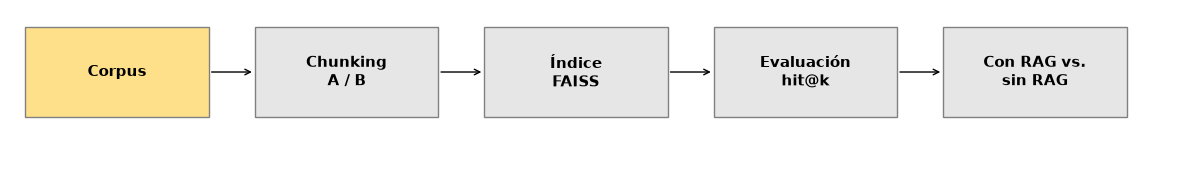

In [4]:
mostrar_progreso("Corpus")

In [5]:
wikipedia.set_lang("es")
wikipedia.set_user_agent("TP1-RAG-ISTEA/1.0 (uso educativo)")

autores = ["Jorge Luis Borges", "Julio Cortázar", "Gabriel García Márquez",
           "Mario Vargas Llosa", "Ernesto Sabato", "Adolfo Bioy Casares"]

# Función para descargar el título y el texto de un artículo (con reintentos)
def descargar_articulo(titulo, intentos=3):
    for intento in range(intentos):
        try:
            pagina = wikipedia.page(titulo, auto_suggest=False)
            return pagina.title, pagina.content
        except Exception as error:
            print(f"Error al descargar '{titulo}' (intento {intento + 1}): {error}")
            time.sleep(5)
    return None, None

In [6]:
# True: usamos la copia del corpus descargada el 27/09 (los mismos textos con los que trabajamos)
# False: volvemos a descargar los artículos desde Wikipedia
USAR_COPIA_GUARDADA = True
CORPUS_GUARDADO = DATOS / "corpus.json"   # copia del 27/09, incluida en el repo

# Función para cargar la copia guardada del corpus
def cargar_copia_guardada():
    with open(CORPUS_GUARDADO, encoding="utf-8") as f:
        return json.load(f)

if USAR_COPIA_GUARDADA:
    corpus = cargar_copia_guardada()
    print("Corpus cargado de la copia guardada del 27/09")
else:
    corpus = []
    for autor in autores:
        titulo, texto = descargar_articulo(autor)
        if texto:
            corpus.append({"titulo": titulo, "texto": texto})
        time.sleep(2)   # pausa entre artículos
    # si falló algún artículo, usamos la copia guardada
    if len(corpus) < len(autores):
        print("No se pudieron descargar todos los artículos: usamos la copia guardada del 27/09")
        corpus = cargar_copia_guardada()

print("Documentos:", len(corpus))
for doc in corpus:
    print(f"- {doc['titulo']}: {len(doc['texto']):,} caracteres")

Corpus cargado de la copia guardada del 27/09
Documentos: 6
- Adolfo Bioy Casares: 26,750 caracteres
- Ernesto Sabato: 32,073 caracteres
- Gabriel García Márquez: 56,942 caracteres
- Jorge Luis Borges: 98,138 caracteres
- Julio Cortázar: 34,901 caracteres
- Mario Vargas Llosa: 59,797 caracteres


**Limpieza.** Revisando los textos encontramos tres tipos de ruido:

- **Secciones finales sin contenido útil:** *Véase también*, *Notas*, *Referencias*, *Bibliografía* y *Enlaces externos* son listas de links y citas. Como siempre están al final del artículo, cortamos el texto donde aparece la primera de ellas.
- **Caracteres invisibles:** Wikipedia deja un carácter invisible (`\u200b`) donde iban las notas al pie.
- **Restos de formato:** referencias numéricas como `[1]` y espacios repetidos.

Los saltos de línea los dejamos como están, porque la estrategia de chunking por párrafos los necesita.

In [7]:
# secciones del final de los artículos que no aportan información
secciones_finales = ["== Véase también ==", "== Notas ==", "== Referencias ==",
                     "== Bibliografía ==", "== Enlaces externos =="]

# Función para limpiar el texto de un artículo
def limpiar_texto(texto):
    # cortar el texto donde empieza cada sección final
    for seccion in secciones_finales:
        if seccion in texto:
            texto = texto[:texto.index(seccion)]
    # sacar los caracteres invisibles y las referencias como [1]
    texto = texto.replace("\u200b", "")
    texto = re.sub(r"\[[0-9]+\]", "", texto)
    # sacar los espacios repetidos
    while "  " in texto:
        texto = texto.replace("  ", " ")
    return texto.strip()

# aplicar la limpieza a todos los documentos
for doc in corpus:
    largo_antes = len(doc["texto"])
    doc["texto"] = limpiar_texto(doc["texto"])
    print(f"- {doc['titulo']}: {largo_antes:,} -> {len(doc['texto']):,} caracteres")

- Adolfo Bioy Casares: 26,750 -> 24,472 caracteres
- Ernesto Sabato: 32,073 -> 31,505 caracteres
- Gabriel García Márquez: 56,942 -> 55,321 caracteres
- Jorge Luis Borges: 98,138 -> 96,226 caracteres
- Julio Cortázar: 34,901 -> 33,731 caracteres
- Mario Vargas Llosa: 59,797 -> 59,178 caracteres


## 5. Estadísticas del corpus

La consigna pide un corpus en español con al menos 5 documentos y 60.000 caracteres.

,Documento,Caracteres,Palabras (aprox.),% del corpus
0,Adolfo Bioy Casares,24472,4053,8.1
1,Ernesto Sabato,31505,5199,10.5
2,Gabriel García Márquez,55321,9084,18.4
3,Jorge Luis Borges,96226,15453,32.0
4,Julio Cortázar,33731,5487,11.2
5,Mario Vargas Llosa,59178,9730,19.7


Cantidad de documentos: 6
Total de caracteres: 300,433
Promedio por documento: 50,072
Cumple los mínimos de la consigna: True


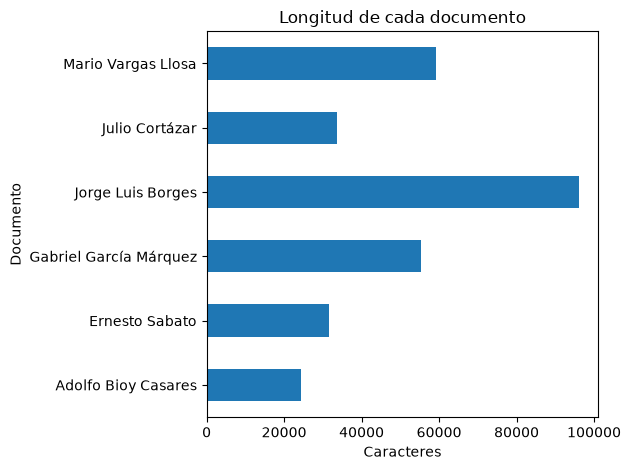

In [8]:
df_stats = pd.DataFrame({
    "Documento": [d["titulo"] for d in corpus],
    "Caracteres": [len(d["texto"]) for d in corpus],
    "Palabras (aprox.)": [len(d["texto"].split()) for d in corpus],
})
df_stats["% del corpus"] = (100 * df_stats["Caracteres"] / df_stats["Caracteres"].sum()).round(1)
display(df_stats)

print("Cantidad de documentos:", len(df_stats))
print(f"Total de caracteres: {df_stats['Caracteres'].sum():,}")
print(f"Promedio por documento: {df_stats['Caracteres'].mean():,.0f}")
print("Cumple los mínimos de la consigna:",
      len(df_stats) >= 5 and df_stats["Caracteres"].sum() >= 60000)

# distribución de longitudes
df_stats.plot.barh(x="Documento", y="Caracteres", legend=False, title="Longitud de cada documento")
plt.xlabel("Caracteres")
plt.tight_layout()
plt.show()

resultados_etapas["Corpus"] = f"{len(corpus)} docs · {df_stats['Caracteres'].sum():,} caracteres"

**Comentario.** El corpus tiene 6 documentos y unos 300.000 caracteres (alrededor de 49.000 palabras). No está balanceado: Borges es el artículo más largo, con cerca del 32% del total, y Bioy Casares el más corto, con un 8%, casi cuatro veces menos. Lo tuvimos en cuenta al analizar el buscador: como Borges tiene muchos más chunks que el resto, tiene más chances de aparecer en los resultados aunque la pregunta sea sobre otro autor. No rebalanceamos el corpus.

## 6. Estrategias de chunking

El modelo de embeddings tiene un límite de tokens, y un vector que resume un artículo entero mezcla demasiados temas. Por eso partimos cada artículo en fragmentos más chicos (*chunks*). Probamos dos estrategias:

- **A — Tamaño fijo:** cortamos cada 500 caracteres, sin mirar dónde cae el corte. Para no perder información en los bordes, cada chunk repite los últimos 100 caracteres del anterior (*overlap*).
- **B — Por párrafos:** juntamos párrafos completos en un mismo chunk hasta llegar a 1000 caracteres. Si un párrafo solo supera ese límite, lo partimos con la estrategia A.

En los dos casos guardamos de qué documento viene cada chunk (`doc_titulo`), para poder calcular `hit@k` y saber de qué artículo salió cada respuesta.

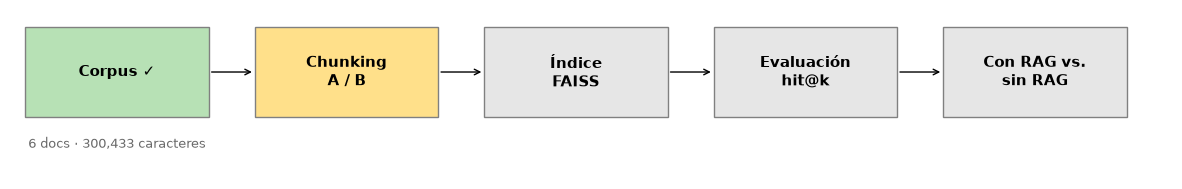

In [9]:
mostrar_progreso("Chunking A/B")

In [10]:
# Función para partir un texto en chunks de tamaño fijo con overlap
def chunking_fijo(texto, tamanio=500, overlap=100):
    chunks = []
    paso = tamanio - overlap

    for inicio in range(0, len(texto), paso):
        chunks.append(texto[inicio:inicio + tamanio])

    return chunks

# Función para partir un texto en chunks respetando los párrafos
def chunking_parrafos(texto, tamanio_max=1000):
    parrafos = [p.strip() for p in texto.split("\n") if p.strip()]
    chunks = []
    chunk_actual = ""

    for parrafo in parrafos:
        if len(parrafo) > tamanio_max:
            if chunk_actual:
                chunks.append(chunk_actual)
                chunk_actual = ""
            chunks.extend(chunking_fijo(parrafo, tamanio=tamanio_max, overlap=100))

        elif len(chunk_actual) + len(parrafo) + 1 <= tamanio_max:
            if chunk_actual:
                chunk_actual += "\n" + parrafo
            else:
                chunk_actual = parrafo

        else:
            chunks.append(chunk_actual)
            chunk_actual = parrafo

    if chunk_actual:
        chunks.append(chunk_actual)

    return chunks

# aplicar las dos estrategias a todo el corpus
chunks_A = []
for doc in corpus:
    for texto_chunk in chunking_fijo(doc["texto"]):
        chunks_A.append({"chunk_id": len(chunks_A), "doc_titulo": doc["titulo"],
                         "texto": texto_chunk, "estrategia": "A"})

chunks_B = []
for doc in corpus:
    for texto_chunk in chunking_parrafos(doc["texto"]):
        chunks_B.append({"chunk_id": len(chunks_B), "doc_titulo": doc["titulo"],
                         "texto": texto_chunk, "estrategia": "B"})

print("Cantidad de chunks (estrategia A):", len(chunks_A))
print("Cantidad de chunks (estrategia B):", len(chunks_B))

resultados_etapas["Chunking A/B"] = f"A: {len(chunks_A)} · B: {len(chunks_B)} chunks"

Cantidad de chunks (estrategia A): 754
Cantidad de chunks (estrategia B): 410


## 7. Comparación de las estrategias de chunking

In [11]:
def resumen_chunks(chunks):
    L = [len(c["texto"]) for c in chunks]
    return [len(L), round(float(np.mean(L)), 1), min(L), max(L)]

comparacion_chunking = pd.DataFrame(
    {"A — Fixed-size": resumen_chunks(chunks_A),
     "B — Paragraph-aware": resumen_chunks(chunks_B)},
    index=["Cantidad de chunks", "Longitud media (caracteres)", "Longitud mínima", "Longitud máxima"],
)
display(comparacion_chunking)

,A — Fixed-size,B — Paragraph-aware
Cantidad de chunks,754.0,410.0
Longitud media (caracteres),497.6,743.6
Longitud mínima,72.0,103.0
Longitud máxima,500.0,1000.0


In [12]:
# cantidad de chunks por documento
por_doc = pd.DataFrame({
    "A — Fixed-size": [sum(1 for c in chunks_A if c["doc_titulo"] == d["titulo"]) for d in corpus],
    "B — Paragraph-aware": [sum(1 for c in chunks_B if c["doc_titulo"] == d["titulo"]) for d in corpus],
}, index=[d["titulo"] for d in corpus])
display(por_doc)

,A — Fixed-size,B — Paragraph-aware
Adolfo Bioy Casares,62,33
Ernesto Sabato,79,46
Gabriel García Márquez,139,73
Jorge Luis Borges,241,133
Julio Cortázar,85,43
Mario Vargas Llosa,148,82


Mostramos tres chunks seguidos de cada estrategia, del mismo artículo (Julio Cortázar), para ver la diferencia.

In [13]:
# Función para mostrar algunos chunks de un documento
def mostrar_chunks(chunks, titulo, desde=0, cantidad=3):
    chunks_doc = [c for c in chunks if c["doc_titulo"] == titulo]

    for c in chunks_doc[desde:desde + cantidad]:
        print(f"--- Chunk {c['chunk_id']} ({len(c['texto'])} caracteres) ---")
        print(c["texto"])
        print()

print("ESTRATEGIA A\n")
mostrar_chunks(chunks_A, "Julio Cortázar", desde=2)
print("ESTRATEGIA B\n")
mostrar_chunks(chunks_B, "Julio Cortázar", desde=1)

ESTRATEGIA A

--- Chunk 523 (500 caracteres) ---
ue uno de los exponentes centrales del boom latinoamericano. Sus ficciones transitan de lo real a lo fantástico, y por ello suele ser relacionado con el surrealismo y el realismo mágico.
Vivió hasta los cuatro años en Bélgica, Suiza y España. Su familia regresó a Argentina, donde Cortázar residiría hasta 1951. Ese año se estableció en Francia, que sirvió a la ambientación de algunas de sus obras y donde vivió el resto de su vida. Visitó por última vez su país a principios de diciembre de 1983, l

--- Chunk 524 (500 caracteres) ---
 donde vivió el resto de su vida. Visitó por última vez su país a principios de diciembre de 1983, luego de las elecciones presidenciales para la recuperación de la democracia. El 7 de diciembre regresó a París. Allí murió dos meses después a causa de una leucemia, aunque algunos autores sostienen la teoría de que murió por complicaciones derivadas del sida por una transfusión de sangre.

== Biografía ==

=== I

**Discusión.** La estrategia A genera casi el doble de chunks que la B (754 contra 410), porque corta cada 500 caracteres y además repite 100 en cada corte. Sus chunks son casi todos iguales de largos; los de B varían bastante, de unos 100 hasta 1000 caracteres.

En los ejemplos de Cortázar se ve la diferencia principal: los chunks de A empiezan y terminan en medio de palabras (*"ue uno de los exponentes…"*, *"…al sur de la ciud"*), mientras que los de B mantienen los párrafos completos, como el chunk sobre la infancia de Cortázar en Banfield. Por eso, a simple vista, B nos pareció la estrategia más prometedora para este corpus.

Vimos dos puntos en contra de B. Sus chunks son más largos (unos 740 caracteres de promedio), y en clase se mencionó que lo que mejor suele funcionar está entre 300 y 600 caracteres, porque los chunks muy grandes "diluyen" la información. Además, en las dos estrategias hay chunks que juntan el final de una sección con el principio de la siguiente (por ejemplo, la introducción con *Biografía*).

En la sección 11 lo comprobamos con `hit@k`: B solo supera a A cuando se agrega el título del artículo al texto de cada chunk.

## 8. Embeddings e índice FAISS

Usamos el modelo `paraphrase-multilingual-mpnet-base-v2`, el mismo de clase: es multilingüe y convierte cada texto en un vector de 768 números, ubicando cerca los textos con significado parecido. Normalizamos los vectores y los guardamos en un índice `faiss.IndexFlatIP`: con vectores normalizados, el producto interno es igual a la similitud coseno.

Antes de calcular los vectores revisamos un detalle: por defecto, el modelo solo lee los primeros 128 tokens de cada texto y descarta el resto sin avisar. Muchos de nuestros chunks son más largos, sobre todo los de B. Por eso subimos el límite a 320 tokens y verificamos que ningún chunk quede cortado.

**Una mejora que probamos: agregar el nombre del autor a cada chunk.** En las primeras pruebas del buscador (sección 9) vimos que el modelo entiende bien *qué* se pregunta ("¿dónde nació…?"), pero le da poco peso a *de quién*. Muchos chunks dicen "su padre" o "el escritor" sin nombrar al autor, así que su vector no sabe de quién habla. Por eso armamos, además, una versión de cada índice en la que le pegamos el título del artículo adelante al texto antes de calcular el vector (`"Julio Cortázar: ..."`). Los chunks y las preguntas no cambian. En total armamos cuatro índices: A, A + título, B y B + título.

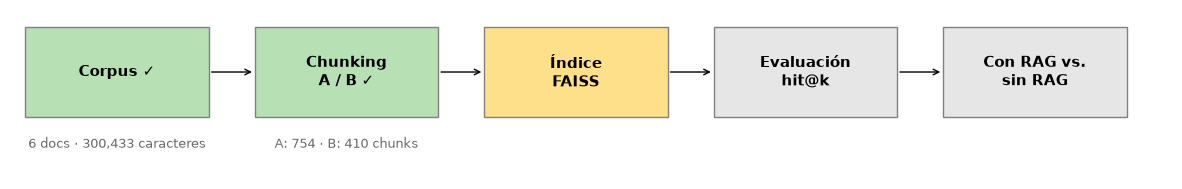

In [14]:
mostrar_progreso("Índice FAISS")

In [15]:
import faiss
from sentence_transformers import SentenceTransformer

# configuración del modelo de embeddings
MODELO_EMBEDDINGS = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MAX_TOKENS = 320

modelo = SentenceTransformer(MODELO_EMBEDDINGS)
modelo.max_seq_length = MAX_TOKENS
print("Dispositivo:", modelo.device)
print("Dimensión de los vectores:", modelo.get_sentence_embedding_dimension())
print("Máximo de tokens por texto:", modelo.max_seq_length)

# Función que arma el texto que se convierte en vector: el chunk solo, o con el título adelante
def texto_para_embedding(chunk, con_titulo=False):
    if con_titulo:
        return f"{chunk['doc_titulo']}: {chunk['texto']}"
    return chunk["texto"]

# control de truncado: ¿algún chunk supera el límite de tokens del modelo?
def contar_tokens(texto):
    return len(modelo.tokenizer(texto)["input_ids"])

filas = []
for nombre, chunks, con_titulo in [("A - tamaño fijo", chunks_A, False),
                                   ("B - párrafos", chunks_B, False),
                                   ("A - tamaño fijo + título", chunks_A, True),
                                   ("B - párrafos + título", chunks_B, True)]:
    tokens = np.array([contar_tokens(texto_para_embedding(c, con_titulo)) for c in chunks])
    filas.append({"variante": nombre,
                  "tokens promedio": round(tokens.mean()),
                  "tokens máximo": int(tokens.max()),
                  f"% truncados (límite {MAX_TOKENS})": round(100 * (tokens > MAX_TOKENS).mean(), 1)})
display(pd.DataFrame(filas))

Dispositivo: cpu
Dimensión de los vectores: 768
Máximo de tokens por texto: 320


,variante,tokens promedio,tokens máximo,% truncados (límite 320)
0,A - tamaño fijo,123,157,0.0
1,B - párrafos,182,297,0.0
2,A - tamaño fijo + título,128,162,0.0
3,B - párrafos + título,187,302,0.0


In [16]:
# Función para construir un índice FAISS (con o sin título)
def construir_indice(chunks, con_titulo=False):
    textos = [texto_para_embedding(c, con_titulo) for c in chunks]
    vectores = modelo.encode(textos, batch_size=32, show_progress_bar=True,
                             normalize_embeddings=True).astype("float32")
    indice = faiss.IndexFlatIP(vectores.shape[1])
    indice.add(vectores)
    return indice

indice_A = construir_indice(chunks_A)
indice_B = construir_indice(chunks_B)
indice_A_tit = construir_indice(chunks_A, con_titulo=True)
indice_B_tit = construir_indice(chunks_B, con_titulo=True)

indices = {"indice_A": (indice_A, chunks_A), "indice_B": (indice_B, chunks_B),
           "indice_A_tit": (indice_A_tit, chunks_A), "indice_B_tit": (indice_B_tit, chunks_B)}

for nombre, (indice, chunks) in indices.items():
    print(f"{nombre}: {indice.ntotal} vectores de {indice.d} dimensiones ({len(chunks)} chunks)")

config_embeddings = pd.Series({
    "Modelo de embeddings": MODELO_EMBEDDINGS,
    "Dimensión de los vectores": modelo.get_sentence_embedding_dimension(),
    "Máximo de tokens": MAX_TOKENS,
    "Tipo de índice": "IndexFlatIP con embeddings normalizados",
    "Vectores en índice A (fixed)": indice_A.ntotal,
    "Vectores en índice B (paragraph-aware)": indice_B.ntotal,
    "Vectores en índices con título (A_tit / B_tit)": f"{indice_A_tit.ntotal} / {indice_B_tit.ntotal}",
}).to_frame("Valor")
display(config_embeddings)

resultados_etapas["Índice FAISS"] = f"{len(indices)} índices · {indice_A.d} dimensiones"

indice_A: 754 vectores de 768 dimensiones (754 chunks)
indice_B: 410 vectores de 768 dimensiones (410 chunks)
indice_A_tit: 754 vectores de 768 dimensiones (754 chunks)
indice_B_tit: 410 vectores de 768 dimensiones (410 chunks)


,Valor
Modelo de embeddings,sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Dimensión de los vectores,768
Máximo de tokens,320
Tipo de índice,IndexFlatIP con embeddings normalizados
Vectores en índice A (fixed),754
Vectores en índice B (paragraph-aware),410
Vectores en índices con título (A_tit / B_tit),754 / 410


## 9. Función de búsqueda

`buscar()` convierte la pregunta en un vector con el mismo modelo, busca en el índice los `k` chunks más parecidos y devuelve cada uno con su `score` de similitud (más alto = más parecido) y su puesto (`rank`).

Cada índice se usa siempre con su propia lista de chunks (`indice_A` e `indice_A_tit` con `chunks_A`; `indice_B` e `indice_B_tit` con `chunks_B`): si se cruzan, la función devuelve textos equivocados sin dar error.

In [17]:
K_DEFAULT = 5   # cuántos chunks devuelve buscar() si no se indica otro valor

# Función para buscar los k chunks más parecidos a una pregunta
def buscar(pregunta, k=K_DEFAULT, indice=indice_B, chunks=chunks_B):
    vector = modelo.encode([pregunta], normalize_embeddings=True).astype("float32")
    scores, posiciones = indice.search(vector, k)   # scores: similitud coseno (más alto = más parecido)

    resultados = []
    for rank, (score, pos) in enumerate(zip(scores[0], posiciones[0]), start=1):
        resultado = dict(chunks[pos])
        resultado["score"] = float(score)
        resultado["rank"] = rank
        resultados.append(resultado)
    return resultados

Probamos tres preguntas en el índice B, sin título:

In [18]:
for pregunta in ["¿Dónde nació Julio Cortázar?",
                 "¿Dónde nació Borges?",
                 "¿Dónde nació Jorge Luis Borges?"]:
    print(pregunta)
    for r in buscar(pregunta, k=5):
        print(f"  {r['rank']}. score={r['score']:.3f} | {r['doc_titulo']} | {r['texto'][:95]}...")
    print()

¿Dónde nació Julio Cortázar?
  1. score=0.767 | Adolfo Bioy Casares | Nació el 15 de septiembre de 1914 en Buenos Aires, siendo el único hijo de Adolfo Bioy Domecq y...
  2. score=0.726 | Julio Cortázar | El abuelo paterno de Julio Cortázar, Pedro Valentín Cortázar, procedía de la localidad vizcaína...
  3. score=0.719 | Ernesto Sabato | Ernesto Roque Sábato nació el 24 de junio de 1911 en la ciudad de Rojas (provincia de Buenos Ai...
  4. score=0.670 | Julio Cortázar | Vivió hasta los cuatro años en Bélgica, Suiza y España. Su familia regresó a Argentina, donde C...
  5. score=0.657 | Jorge Luis Borges | Jorge Luis nació el 24 de agosto de 1899 a los ocho meses de gestación, en una casa porteña de ...

¿Dónde nació Borges?
  1. score=0.672 | Jorge Luis Borges | En 1905 comenzó a tomar sus primeras lecciones con una institutriz británica. Al año siguiente ...
  2. score=0.655 | Jorge Luis Borges | == Fallecimiento ==
Borges falleció el 14 de junio de 1986 a los 86 años víctima de un cá

- En *"¿Dónde nació Julio Cortázar?"* el primer resultado es un chunk de Bioy Casares que también habla de un nacimiento, y el chunk de Cortázar con su lugar de nacimiento recién aparece en el puesto 4.
- En *"¿Dónde nació Borges?"* los cinco resultados son de Borges, pero ninguno habla de su nacimiento: el apellido solo pesó más que el resto de la pregunta.
- En *"¿Dónde nació Jorge Luis Borges?"* acierta el primer puesto, pero los chunks de Sabato y Bioy Casares quedan casi empatados.

Estos casos nos llevaron a armar los índices con título (sección 8). Son solo tres ejemplos: la comparación en serio la hacemos con `hit@k` en la sección 11.

## 10. Set de evaluación de 10 preguntas

Armamos 10 preguntas con respuesta concreta, repartidas entre los seis autores. Cada una tiene anotado el documento donde está la respuesta (`documento_fuente`, escrito igual que el título del artículo) y la respuesta esperada, que usamos después para calificar las respuestas del LLM.

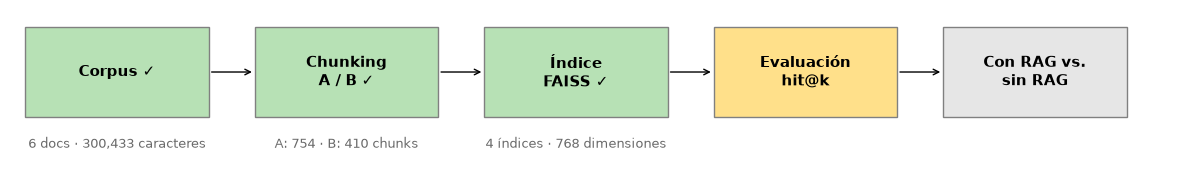

In [19]:
mostrar_progreso("Evaluación hit@k")

In [20]:
preguntas_eval = [
    {"pregunta": "¿Dónde nació Jorge Luis Borges?",
     "documento_fuente": "Jorge Luis Borges", "respuesta_esperada": "Buenos Aires, Argentina"},
    {"pregunta": "¿En qué año nació Jorge Luis Borges?",
     "documento_fuente": "Jorge Luis Borges", "respuesta_esperada": "1899"},
    {"pregunta": "¿Dónde nació Julio Cortázar?",
     "documento_fuente": "Julio Cortázar", "respuesta_esperada": "Ixelles, Bélgica"},
    {"pregunta": "¿Cuál es la obra más conocida de Julio Cortázar?",
     "documento_fuente": "Julio Cortázar", "respuesta_esperada": "Rayuela"},
    {"pregunta": "¿Qué premio recibió Gabriel García Márquez en 1982?",
     "documento_fuente": "Gabriel García Márquez", "respuesta_esperada": "Premio Nobel de Literatura"},
    {"pregunta": "¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?",
     "documento_fuente": "Gabriel García Márquez", "respuesta_esperada": "Cien años de soledad"},
    {"pregunta": "¿En qué país nació Mario Vargas Llosa?",
     "documento_fuente": "Mario Vargas Llosa", "respuesta_esperada": "Perú"},
    {"pregunta": "¿Qué premio recibió Mario Vargas Llosa en 2010?",
     "documento_fuente": "Mario Vargas Llosa", "respuesta_esperada": "Premio Nobel de Literatura"},
    {"pregunta": "¿Dónde nació Ernesto Sábato?",
     "documento_fuente": "Ernesto Sabato", "respuesta_esperada": "Rojas, Provincia de Buenos Aires"},
    {"pregunta": "¿Con qué escritor colaboró frecuentemente Adolfo Bioy Casares?",
     "documento_fuente": "Adolfo Bioy Casares", "respuesta_esperada": "Jorge Luis Borges"},
]

In [21]:
df_preguntas = pd.DataFrame(preguntas_eval)
df_preguntas.insert(0, "N°", range(1, len(df_preguntas) + 1))

# control: cada documento_fuente tiene que ser el título de un documento del corpus
titulos_corpus = {d["titulo"] for d in corpus}
assert all(p["documento_fuente"] in titulos_corpus for p in preguntas_eval), \
    "Algún documento_fuente no coincide con un título del corpus"

print("Cantidad de preguntas:", len(df_preguntas), "(mínimo exigido: 10)")
display(df_preguntas)
display(df_preguntas["documento_fuente"].value_counts().to_frame("preguntas"))

Cantidad de preguntas: 10 (mínimo exigido: 10)


,N°,pregunta,documento_fuente,respuesta_esperada
0,1,¿Dónde nació Jorge Luis Borges?,Jorge Luis Borges,"Buenos Aires, Argentina"
1,2,¿En qué año nació Jorge Luis Borges?,Jorge Luis Borges,1899
2,3,¿Dónde nació Julio Cortázar?,Julio Cortázar,"Ixelles, Bélgica"
3,4,¿Cuál es la obra más conocida de Julio Cortázar?,Julio Cortázar,Rayuela
4,5,¿Qué premio recibió Gabriel García Márquez en 1982?,Gabriel García Márquez,Premio Nobel de Literatura
5,6,¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?,Gabriel García Márquez,Cien años de soledad
6,7,¿En qué país nació Mario Vargas Llosa?,Mario Vargas Llosa,Perú
7,8,¿Qué premio recibió Mario Vargas Llosa en 2010?,Mario Vargas Llosa,Premio Nobel de Literatura
8,9,¿Dónde nació Ernesto Sábato?,Ernesto Sabato,"Rojas, Provincia de Buenos Aires"
9,10,¿Con qué escritor colaboró frecuentemente Adolfo Bioy Casares?,Adolfo Bioy Casares,Jorge Luis Borges


,preguntas
documento_fuente,
Jorge Luis Borges,2
Julio Cortázar,2
Gabriel García Márquez,2
Mario Vargas Llosa,2
Ernesto Sabato,1
Adolfo Bioy Casares,1


## 11. Resultados del buscador

Usamos dos métricas:

- **hit@k:** una pregunta es un *hit* si al menos uno de los `k` primeros chunks viene del documento correcto. Lo medimos para k = 1, 3 y 5.
- **precisión@5:** de los 5 chunks recuperados, qué proporción viene del documento correcto. Es más exigente que hit@5, porque premia que el buscador traiga *varios* chunks útiles, que es lo que después recibe el LLM como contexto.

La consigna pide comparar A y B; A + título y B + título son las variantes que agregamos.

,hit@1,hit@3,hit@5,precisión@5
A — Fixed-size,0.9,1.0,1.0,0.76
A + título,0.9,1.0,1.0,0.96
B — Paragraph-aware,0.8,1.0,1.0,0.58
B + título,1.0,1.0,1.0,0.88


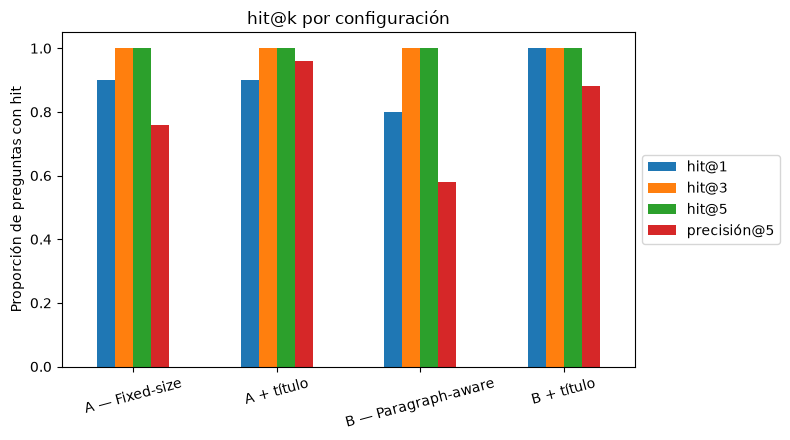

,A — Fixed-size,A + título,B — Paragraph-aware,B + título
1. ¿Dónde nació Jorge Luis Borges?,1,1,1,1
2. ¿En qué año nació Jorge Luis Borges?,1,1,1,1
3. ¿Dónde nació Julio Cortázar?,1,1,2,1
4. ¿Cuál es la obra más conocida de Julio Cortázar?,1,1,2,1
5. ¿Qué premio recibió Gabriel García Márquez en 1982?,1,1,1,1
6. ¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?,1,1,1,1
7. ¿En qué país nació Mario Vargas Llosa?,1,1,1,1
8. ¿Qué premio recibió Mario Vargas Llosa en 2010?,1,1,1,1
9. ¿Dónde nació Ernesto Sábato?,3,2,1,1
10. ¿Con qué escritor colaboró frecuentemente Adolfo Bioy Casares?,1,1,1,1


In [22]:
INDICES = {
    "A — Fixed-size": (indice_A, chunks_A),
    "A + título": (indice_A_tit, chunks_A),
    "B — Paragraph-aware": (indice_B, chunks_B),
    "B + título": (indice_B_tit, chunks_B),
}
KS = (1, 3, 5)

# Función para evaluar un índice con las 10 preguntas
def evaluar_indice(indice, chunks):
    # para cada pregunta: puesto del primer chunk del documento correcto (None si no está en el top 5)
    puestos = []
    precision = 0
    for p in preguntas_eval:
        res = buscar(p["pregunta"], k=max(KS), indice=indice, chunks=chunks)
        puesto = next((r["rank"] for r in res if r["doc_titulo"] == p["documento_fuente"]), None)
        puestos.append(puesto)
        # precisión@5: proporción de los 5 chunks que vienen del documento correcto
        precision += sum(1 for r in res if r["doc_titulo"] == p["documento_fuente"]) / max(KS)
    hits = {f"hit@{k}": sum(1 for x in puestos if x is not None and x <= k) / len(puestos) for k in KS}
    hits["precisión@5"] = precision / len(puestos)
    return hits, puestos

HIT, PUESTOS = {}, {}
for nombre, (indice, chunks) in INDICES.items():
    HIT[nombre], PUESTOS[nombre] = evaluar_indice(indice, chunks)

tabla_hit = pd.DataFrame(HIT).T
display(tabla_hit.round(2))

tabla_hit.plot.bar(rot=15, ylim=(0, 1.05), title="hit@k por configuración", figsize=(8, 4.5))
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))   # leyenda afuera, para que no tape las barras
plt.ylabel("Proporción de preguntas con hit"); plt.tight_layout(); plt.show()

# detalle: puesto del primer chunk correcto en cada pregunta ("—" = no aparece en el top 5)
detalle = pd.DataFrame(
    {nombre: [x if x is not None else "—" for x in v] for nombre, v in PUESTOS.items()},
    index=[f"{i+1}. {p['pregunta']}" for i, p in enumerate(preguntas_eval)])
display(detalle)

ganador = tabla_hit["hit@1"].idxmax()
resultados_etapas["Evaluación hit@k"] = f"gana {ganador} (hit@1 = {tabla_hit.loc[ganador, 'hit@1']:.1f})"

**Análisis.** Con las 10 preguntas, el documento correcto aparece siempre entre los 3 primeros chunks en las cuatro configuraciones (`hit@3` = `hit@5` = 1,0), así que esas dos métricas no las distinguen. La diferencia está en `hit@1`:

- **B + título** es la única configuración con `hit@1` perfecto (1,0).
- **A y A + título** quedan en 0,9: fallan en el primer puesto la pregunta 9 (¿dónde nació Sabato?).
- **B** queda en 0,8: falla en el primer puesto las dos preguntas sobre Cortázar (3 y 4).

**¿Qué combinación ganó?** B + título. Por eso es el índice que usamos para generar las respuestas con RAG.

**¿Cuánto mejora la estrategia por párrafos sobre la de tamaño fijo?** Depende del título. Sin título, B no mejora a A: queda una pregunta abajo (0,8 contra 0,9), algo que relacionamos con el tamaño más grande de sus chunks. Con título, B queda una pregunta arriba (1,0 contra 0,9). En nuestro caso, agregar el nombre del autor influyó más que la estrategia de chunking.

La precisión@5 muestra algo que `hit@k` no ve: cuántos de los 5 chunks recuperados son del autor correcto, que es el contexto que después recibe el LLM. Ahí el efecto del título se ve todavía más claro: A pasa de 0,76 a 0,96 y B de 0,58 a 0,88. B sin título es la configuración con menos chunks del autor correcto (0,58), lo que coincide con lo que vimos en `hit@1`.

Con 10 preguntas, cada una vale 10 puntos porcentuales: estas diferencias son de una o dos preguntas y hay que tomarlas como orientativas.

## 12. Generación con RAG

Usamos `Qwen/Qwen2.5-1.5B-Instruct`, un LLM open-source chico que entra en la GPU T4 de Colab. Lo cargamos en media precisión (`float16`) para que ocupe menos memoria, y generamos sin muestreo (`do_sample=False`): el modelo siempre elige la palabra más probable, así las respuestas son las mismas cada vez que corremos el notebook.

`responder_con_rag()` busca los 3 chunks más parecidos en el índice B + título y se los pasa al modelo como contexto, con un **prompt de grounding**: tiene que responder usando únicamente ese contexto y, si la respuesta no está, decir *"No tengo información suficiente"*.

**Respuestas guardadas.** Con `GENERAR = False` (el valor por defecto) el notebook no carga el LLM: `responder_con_rag()` y `responder_sin_rag()` hacen todo el proceso (incluida la búsqueda de los chunks), pero en lugar de generar devuelven la respuesta que dio el modelo cuando corrimos el notebook en Colab con GPU T4, guardada en `resultados/respuestas_llm.json`. Como generamos sin muestreo, son las mismas respuestas que se obtienen con `GENERAR = True`, y así el notebook corre en cualquier computadora sin GPU.

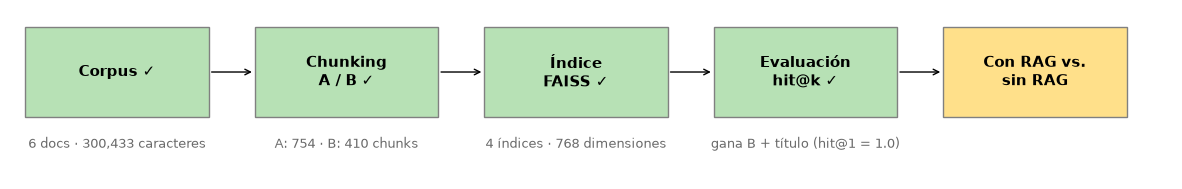

In [23]:
mostrar_progreso("Con RAG vs. sin RAG")

In [24]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_NEW_TOKENS = 320

if GENERAR:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        tokenizer.pad_token_id = tokenizer.eos_token_id

    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16, device_map="auto")
    print("Dispositivo del LLM:", model.device)
else:
    # respuestas que dio el LLM al correr el notebook en Colab (GPU T4), sin muestreo
    with open(RESULTADOS / "respuestas_llm.json", encoding="utf-8") as f:
        RESPUESTAS_GUARDADAS = json.load(f)
    print("GENERAR = False: usamos las respuestas guardadas en resultados/respuestas_llm.json")

# Función para generar una respuesta a partir de un prompt
def generar_respuesta(prompt, max_new_tokens=MAX_NEW_TOKENS):
    mensajes = [{"role": "user", "content": prompt}]
    texto_entrada = tokenizer.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(texto_entrada, return_tensors="pt").to(model.device)
    output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                            pad_token_id=tokenizer.eos_token_id)
    tokens_generados = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(tokens_generados, skip_special_tokens=True).strip()

GENERAR = False: usamos las respuestas guardadas en resultados/respuestas_llm.json


In [25]:
K_CONTEXTO = 3   # chunks que se pasan como contexto al LLM

# Función para responder usando los chunks recuperados como contexto
def responder_con_rag(pregunta, k=K_CONTEXTO, indice=indice_B_tit, chunks=chunks_B):
    resultados = buscar(pregunta, k, indice=indice, chunks=chunks)
    contexto = "\n\n".join([r["texto"] for r in resultados])
    prompt = f"""Respondé la pregunta usando ÚNICAMENTE la información del contexto que aparece abajo.
No uses conocimiento propio ni información externa al contexto.
Si la respuesta no se encuentra en el contexto, respondé exactamente: "No tengo información suficiente".
Respondé de forma breve y directa.

Contexto:
{contexto}

Pregunta: {pregunta}

Respuesta:"""
    if not GENERAR:
        return RESPUESTAS_GUARDADAS["con_rag"][pregunta]
    return generar_respuesta(prompt)

config_generacion = pd.Series({
    "LLM utilizado": MODEL_NAME,
    "Chunking / índice usado para el retrieval": "B + título (indice_B_tit con chunks_B)",
    "k (chunks en el contexto)": K_CONTEXTO,
    "Parámetros de generación": f"sin muestreo (determinístico), máximo {MAX_NEW_TOKENS} tokens nuevos",
    "Prompt de grounding": "responder solo con el contexto; si no está, decir 'No tengo información suficiente'",
}).to_frame("Valor")
display(config_generacion)

print(responder_con_rag("¿Dónde nació Julio Cortázar?"))

,Valor
LLM utilizado,Qwen/Qwen2.5-1.5B-Instruct
Chunking / índice usado para el retrieval,B + título (indice_B_tit con chunks_B)
k (chunks en el contexto),3
Parámetros de generación,"sin muestreo (determinístico), máximo 320 tokens nuevos"
Prompt de grounding,"responder solo con el contexto; si no está, decir 'No tengo información suficiente'"


Julio Cortázar nació en Ixelles, un municipio al sur de la ciudad de Bruselas, Bélgica.


## 13. Generación sin RAG

`responder_sin_rag()` le pasa al mismo modelo solo la pregunta, sin contexto, con los mismos parámetros de generación.

In [26]:
# Función para responder sin contexto
def responder_sin_rag(pregunta):
    prompt = f"Respondé la siguiente pregunta de forma breve y directa (2-3 oraciones como máximo).\n\nPregunta: {pregunta}"
    if not GENERAR:
        return RESPUESTAS_GUARDADAS["sin_rag"][pregunta]
    return generar_respuesta(prompt)

print(responder_sin_rag("¿Dónde nació Julio Cortázar?"))

Julio Cortázar nació en Buenos Aires, Argentina.


Antes de correr las 10 preguntas, probamos una pregunta inventada, cuya respuesta no existe, para ver si el prompt de grounding funciona.

In [27]:
pregunta_inventada = "¿En qué año terminó Julio Cortázar sus estudios de Ciencia de Datos?"

print("SIN RAG:", responder_sin_rag(pregunta_inventada))
print("CON RAG:", responder_con_rag(pregunta_inventada))

SIN RAG: Julio Cortázar concluyó sus estudios de Ciencia de Datos en el año 1975.
CON RAG: No tengo información suficiente.


Sin contexto, el modelo inventa un año con total seguridad (1975). Con RAG, como el dato no está en los chunks recuperados, responde que no tiene información suficiente: el prompt de grounding cumple su función.

## 14. Evaluación de las respuestas (C/P/I/A)

Calificamos cada respuesta a mano, comparándola con la respuesta esperada:

- **C — Correcta:** el dato pedido está y es correcto.
- **P — Parcial:** va en la dirección correcta, pero le falta precisión u omite parte de la respuesta.
- **I — Incorrecta:** responde algo distinto de lo esperado, sin inventar un dato falso.
- **A — Alucinación:** inventa un dato concreto y falso (un lugar, un año, una obra) que no está en el corpus ni es cierto.

In [28]:
# Respuestas del LLM a las 10 preguntas, SIN y CON RAG
respuestas_sin = [responder_sin_rag(p["pregunta"]) for p in preguntas_eval]
respuestas_con = [responder_con_rag(p["pregunta"]) for p in preguntas_eval]

for i, p in enumerate(preguntas_eval, start=1):
    print(f"{i}. {p['pregunta']}")
    print(f"   Esperada: {p['respuesta_esperada']}")
    print(f"   SIN RAG:  {respuestas_sin[i-1]}")
    print(f"   CON RAG:  {respuestas_con[i-1]}\n")

1. ¿Dónde nació Jorge Luis Borges?
   Esperada: Buenos Aires, Argentina
   SIN RAG:  Jorge Luis Borges nació en Mendoza, Argentina.
   CON RAG:  Palermo, Argentina.

2. ¿En qué año nació Jorge Luis Borges?
   Esperada: 1899
   SIN RAG:  Jorge Luis Borges nació en 1899.
   CON RAG:  1899

3. ¿Dónde nació Julio Cortázar?
   Esperada: Ixelles, Bélgica
   SIN RAG:  Julio Cortázar nació en Buenos Aires, Argentina.
   CON RAG:  Julio Cortázar nació en Ixelles, un municipio al sur de la ciudad de Bruselas, Bélgica.

4. ¿Cuál es la obra más conocida de Julio Cortázar?
   Esperada: Rayuela
   SIN RAG:  La obra más conocida de Julio Cortázar es "Ficciones".
   CON RAG:  Rayuela

5. ¿Qué premio recibió Gabriel García Márquez en 1982?
   Esperada: Premio Nobel de Literatura
   SIN RAG:  Gabriel García Márquez ganó el Premio Nobel de Literatura en 1982.
   CON RAG:  Medalla de la Legión de Honor de Francia en París.

6. ¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?
   Espera

Para dos respuestas con RAG revisamos qué tenían los chunks que recibió el modelo, porque la calificación no era obvia:

In [29]:
# ¿Aparecen "Palermo" (pregunta 1) y "Legión" (pregunta 5) en los 3 chunks que recibió el LLM?
for idx, palabra in [(0, "Palermo"), (4, "Legión")]:
    p = preguntas_eval[idx]
    res = buscar(p["pregunta"], 3, indice=indice_B_tit, chunks=chunks_B)
    print(f"Pregunta {idx+1}: {p['pregunta']}")
    for r in res:
        esta = palabra.lower() in r["texto"].lower()
        print(f"  puesto {r['rank']} | {r['doc_titulo']} | ¿contiene '{palabra}'? {esta}")
        if esta:
            i = r["texto"].lower().index(palabra.lower())
            print("     ...", r["texto"][max(0, i - 150): i + 200].replace("\n", " "), "...")
    print()

# ¿Está "Legión de Honor" en el texto completo del documento de García Márquez?
gm = next(d["texto"] for d in corpus if d["titulo"] == "Gabriel García Márquez")
print("¿'Legión de Honor' en el documento de García Márquez?", "Legión de Honor" in gm)

Pregunta 1: ¿Dónde nació Jorge Luis Borges?
  puesto 1 | Jorge Luis Borges | ¿contiene 'Palermo'? True
     ... us poesías. Su casa natal estaba en la calle Tucumán 840, pero su infancia transcurrió un poco más al norte, en Serrano 2135, en el barrio porteño de Palermo.[cita requerida] Su relación con la literatura comenzó a muy temprana edad: a los cuatro años ya sabía leer y escribir. Diría, ya con 71 años, que «si tuviera que señalar el hecho capital de m ...
  puesto 2 | Jorge Luis Borges | ¿contiene 'Palermo'? False
  puesto 3 | Jorge Luis Borges | ¿contiene 'Palermo'? True
     ... Nacido en Palermo (en aquel entonces un suburbio de Buenos Aires), Borges se trasladó en la adolescencia con su familia a Suiza, donde residió durante cuatro años, estudiando en el Collège de Genève. La familia ...

Pregunta 5: ¿Qué premio recibió Gabriel García Márquez en 1982?
  puesto 1 | Gabriel García Márquez | ¿contiene 'Legión'? False
  puesto 2 | Gabriel García Márquez | ¿contiene 'Legión'? Tru

In [30]:
# notas C/P/I/A, en el orden de las preguntas
notas_sin = ["A", "C", "A", "A", "C", "C", "C", "C", "P", "C"]
notas_con = ["C", "C", "C", "C", "I", "C", "C", "C", "C", "C"]

EVAL = pd.DataFrame({
    "N°": range(1, 11),
    "Pregunta": [p["pregunta"] for p in preguntas_eval],
    "Respuesta esperada": [p["respuesta_esperada"] for p in preguntas_eval],
    "Respuesta SIN RAG": respuestas_sin,
    "Nota SIN RAG": notas_sin,
    "Respuesta CON RAG": respuestas_con,
    "Nota CON RAG": notas_con,
})
display(EVAL)

,N°,Pregunta,Respuesta esperada,Respuesta SIN RAG,Nota SIN RAG,Respuesta CON RAG,Nota CON RAG
0,1,¿Dónde nació Jorge Luis Borges?,"Buenos Aires, Argentina","Jorge Luis Borges nació en Mendoza, Argentina.",A,"Palermo, Argentina.",C
1,2,¿En qué año nació Jorge Luis Borges?,1899,Jorge Luis Borges nació en 1899.,C,1899,C
2,3,¿Dónde nació Julio Cortázar?,"Ixelles, Bélgica","Julio Cortázar nació en Buenos Aires, Argentina.",A,"Julio Cortázar nació en Ixelles, un municipio al sur de la ciudad de Bruselas, Bélgica.",C
3,4,¿Cuál es la obra más conocida de Julio Cortázar?,Rayuela,"La obra más conocida de Julio Cortázar es ""Ficciones"".",A,Rayuela,C
4,5,¿Qué premio recibió Gabriel García Márquez en 1982?,Premio Nobel de Literatura,Gabriel García Márquez ganó el Premio Nobel de Literatura en 1982.,C,Medalla de la Legión de Honor de Francia en París.,I
5,6,¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?,Cien años de soledad,"Gabriel García Márquez escribió ""Cien años de soledad"" sobre la familia Buendía.",C,Cien años de soledad,C
6,7,¿En qué país nació Mario Vargas Llosa?,Perú,Mario Vargas Llosa nació en Perú.,C,Perú,C
7,8,¿Qué premio recibió Mario Vargas Llosa en 2010?,Premio Nobel de Literatura,Mario Vargas Llosa ganó el Premio Nobel de Literatura en 2010.,C,Nobel de Literatura,C
8,9,¿Dónde nació Ernesto Sábato?,"Rojas, Provincia de Buenos Aires","Ernesto Sábato nació en Buenos Aires, Argentina.",P,"Rojas, Buenos Aires",C
9,10,¿Con qué escritor colaboró frecuentemente Adolfo Bioy Casares?,Jorge Luis Borges,Adolfo Bioy Casares colaboró con Jorge Luis Borges frecuentemente.,C,Con Jorge Luis Borges colaboró frecuentemente Adolfo Bioy Casares.,C


**Casos que discutimos en el grupo:**
- **Pregunta 1 con RAG ("Palermo"):** la calificamos como **C**. No nombra a Buenos Aires, pero uno de los chunks dice que Borges nació en Palermo, entonces un suburbio de Buenos Aires: el dato es correcto y más preciso que el esperado.
- **Pregunta 5 con RAG ("Medalla de la Legión de Honor de Francia"):** la calificamos como **I** y no como alucinación. El dato no es inventado: está en uno de los chunks, en una lista de distinciones, pero es de 1981 y no es el premio por el que se preguntaba (el Nobel de 1982).

## 15. Comparación con RAG y sin RAG

,CON RAG (n),CON RAG (%),SIN RAG (n),SIN RAG (%)
C — Correcta,9,90.0,6,60.0
P — Parcial,0,0.0,1,10.0
I — Incorrecta,1,10.0,0,0.0
A — Alucinación,0,0.0,3,30.0


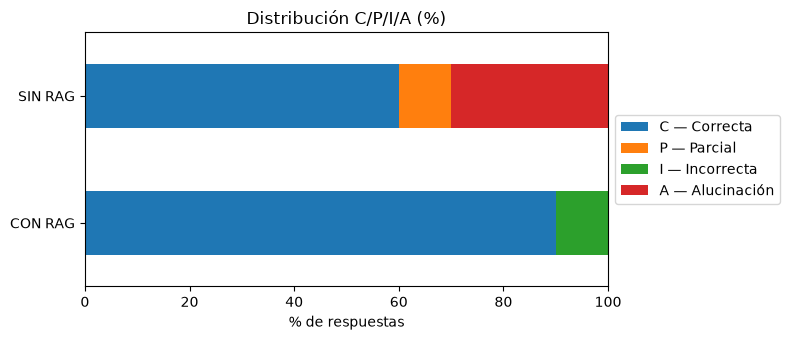

In [31]:
NOMBRES = {"C": "C — Correcta", "P": "P — Parcial", "I": "I — Incorrecta", "A": "A — Alucinación"}

# Función para contar cuántas respuestas hay de cada categoría
def contar(col):
    return EVAL[col].value_counts().reindex(list(NOMBRES), fill_value=0)

c_rag, c_sin = contar("Nota CON RAG"), contar("Nota SIN RAG")

tabla_cpia = pd.DataFrame({
    "CON RAG (n)": c_rag, "CON RAG (%)": (c_rag / c_rag.sum() * 100).round(1),
    "SIN RAG (n)": c_sin, "SIN RAG (%)": (c_sin / c_sin.sum() * 100).round(1),
})
tabla_cpia.index = list(NOMBRES.values())
display(tabla_cpia)
pct = tabla_cpia[["CON RAG (%)", "SIN RAG (%)"]].T
pct.columns = list(NOMBRES.values())
pct.index = ["CON RAG", "SIN RAG"]
pct.plot.barh(stacked=True, title="Distribución C/P/I/A (%)", figsize=(8, 3.5))
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))   # leyenda afuera, para que no tape las barras
plt.xlabel("% de respuestas"); plt.tight_layout(); plt.show()

resultados_etapas["Con RAG vs. sin RAG"] = (f"correctas {c_sin['C']} → {c_rag['C']} · "
                                          f"alucinaciones {c_sin['A']} → {c_rag['A']}")

**Comentario.** Sin RAG, el modelo responde bien 6 de las 10 preguntas (60%), una de forma parcial (10%) y alucina en 3 (30%): inventa dónde nacieron Borges (Mendoza) y Cortázar (Buenos Aires), y da *Ficciones*, que es de Borges, como la obra más conocida de Cortázar. Con RAG responde bien 9 de 10 (90%) y no alucina; la restante es incorrecta (10%).

Pregunta por pregunta, RAG corrigió las tres alucinaciones (1, 3 y 4) y la respuesta parcial (9), mantuvo bien otras cinco y empeoró una (5): sin contexto el modelo acertó el Nobel de 1982 y con contexto eligió otra distinción de la lista.

Hay que tener en cuenta dos cosas al leer estos números: el índice de RAG (B + título) lo elegimos mirando el `hit@1` de estas mismas preguntas, y los prompts no son idénticos (sin RAG pide 2-3 oraciones; con RAG, una respuesta breve y directa).

### Tres preguntas con las dos respuestas lado a lado

Elegimos tres casos distintos: uno en el que RAG corrige una alucinación (3), uno en el que empeora la respuesta (5) y uno en el que pasa de parcial a correcta (9).

In [32]:
elegidas = [2, 4, 8]   # preguntas 3, 5 y 9
lado_a_lado = EVAL.iloc[elegidas][["N°", "Pregunta", "Respuesta esperada",
                                   "Respuesta SIN RAG", "Nota SIN RAG",
                                   "Respuesta CON RAG", "Nota CON RAG"]].copy()
lado_a_lado["Comentario cualitativo"] = [
    "Sin RAG inventa un lugar creíble (Buenos Aires). Con RAG responde Ixelles, Bélgica, que es lo que dice el chunk recuperado: RAG corrige la alucinación.",
    "Sin RAG acierta el Nobel, un dato muy conocido. Con RAG el contexto trae una lista de premios y el modelo elige otro (la Legión de Honor, de 1981): acá RAG empeora la respuesta.",
    "Sin RAG responde Buenos Aires: acierta la provincia pero no la ciudad. Con RAG responde Rojas, la ciudad correcta.",
]
display(lado_a_lado)

,N°,Pregunta,Respuesta esperada,Respuesta SIN RAG,Nota SIN RAG,Respuesta CON RAG,Nota CON RAG,Comentario cualitativo
2,3,¿Dónde nació Julio Cortázar?,"Ixelles, Bélgica","Julio Cortázar nació en Buenos Aires, Argentina.",A,"Julio Cortázar nació en Ixelles, un municipio al sur de la ciudad de Bruselas, Bélgica.",C,"Sin RAG inventa un lugar creíble (Buenos Aires). Con RAG responde Ixelles, Bélgica, que es lo que dice el chunk recuperado: RAG corrige la alucinación."
4,5,¿Qué premio recibió Gabriel García Márquez en 1982?,Premio Nobel de Literatura,Gabriel García Márquez ganó el Premio Nobel de Literatura en 1982.,C,Medalla de la Legión de Honor de Francia en París.,I,"Sin RAG acierta el Nobel, un dato muy conocido. Con RAG el contexto trae una lista de premios y el modelo elige otro (la Legión de Honor, de 1981): acá RAG empeora la respuesta."
8,9,¿Dónde nació Ernesto Sábato?,"Rojas, Provincia de Buenos Aires","Ernesto Sábato nació en Buenos Aires, Argentina.",P,"Rojas, Buenos Aires",C,"Sin RAG responde Buenos Aires: acierta la provincia pero no la ciudad. Con RAG responde Rojas, la ciudad correcta."


### Guardado de resultados

Guardamos las tablas principales en `runs/entrega/`. En el repo, la carpeta `resultados/` tiene una copia de estos archivos.

In [33]:
SALIDA.mkdir(parents=True, exist_ok=True)
tabla_hit.round(2).to_csv(SALIDA / "tabla_hit_k.csv", index_label="configuracion")
detalle.to_csv(SALIDA / "puestos_por_pregunta.csv", index_label="pregunta")
EVAL.to_csv(SALIDA / "respuestas_con_sin_rag.csv", index=False)
tabla_cpia.to_csv(SALIDA / "tabla_CPIA.csv", index_label="categoria")
# respuestas del LLM en el mismo formato que resultados/respuestas_llm.json
with open(SALIDA / "respuestas_llm.json", "w", encoding="utf-8") as f:
    json.dump({"con_rag": {p["pregunta"]: r for p, r in zip(preguntas_eval, respuestas_con)},
               "sin_rag": {p["pregunta"]: r for p, r in zip(preguntas_eval, respuestas_sin)}},
              f, ensure_ascii=False, indent=2)
print("Archivos guardados en", SALIDA.relative_to(RAIZ))
for archivo in sorted(SALIDA.iterdir()):
    print("-", archivo.name)

Archivos guardados en runs\entrega
- puestos_por_pregunta.csv
- respuestas_con_sin_rag.csv
- respuestas_llm.json
- tabla_CPIA.csv
- tabla_hit_k.csv


## 16. Reporte final

En esta sección juntamos los resultados del trabajo, siguiendo los cinco puntos que pide la consigna.

### 1. Corpus y objetivos

Trabajamos con seis artículos de Wikipedia en español sobre autores de la literatura latinoamericana (Borges, Cortázar, García Márquez, Vargas Llosa, Sabato y Bioy Casares), que suman unos 300.000 caracteres después de la limpieza. Son biografías con una estructura muy parecida, así que el buscador tiene que distinguir entre textos que hablan de nacimientos, obras y premios. Las preguntas que esperamos responder son datos concretos sobre cada autor: dónde y cuándo nació, sus obras más conocidas, los premios que recibió y con quién trabajó.

### 2. Resultados del buscador

| Configuración | hit@1 | hit@3 | hit@5 | precisión@5 |
|---|---|---|---|---|
| A — Tamaño fijo | 0,9 | 1,0 | 1,0 | 0,76 |
| A + título | 0,9 | 1,0 | 1,0 | 0,96 |
| B — Por párrafos | 0,8 | 1,0 | 1,0 | 0,58 |
| B + título | **1,0** | 1,0 | 1,0 | 0,88 |

**Ganó B + título**, la única configuración que acertó el primer resultado en las 10 preguntas. Creemos que gana por la combinación de dos cosas: los chunks por párrafos mantienen las ideas completas, y el nombre del autor en cada chunk le da al vector el dato de *quién* habla, que era justamente lo que fallaba. Sin el título, la estrategia por párrafos quedó una pregunta por debajo de la de tamaño fijo y es la que trae menos chunks del autor correcto (precisión@5 de 0,58). Con 10 preguntas, estas diferencias son de una o dos preguntas y las tomamos como orientativas.

### 3. Resultados de la generación

| | Con RAG | Sin RAG |
|---|---|---|
| C — Correcta | 9 (90%) | 6 (60%) |
| P — Parcial | 0 | 1 (10%) |
| I — Incorrecta | 1 (10%) | 0 |
| A — Alucinación | 0 | 3 (30%) |

Tres preguntas con las dos respuestas lado a lado:

| Pregunta | Sin RAG | Con RAG | Qué muestra |
|---|---|---|---|
| ¿Dónde nació Julio Cortázar? | "Buenos Aires, Argentina" (A) | "Ixelles, … Bruselas, Bélgica" (C) | RAG corrige una alucinación |
| ¿Qué premio recibió García Márquez en 1982? | "Premio Nobel de Literatura" (C) | "Medalla de la Legión de Honor de Francia" (I) | RAG empeora: elige otro premio de la lista que recibió |
| ¿Dónde nació Ernesto Sabato? | "Buenos Aires, Argentina" (P) | "Rojas, Buenos Aires" (C) | RAG agrega precisión |

Con RAG, el modelo pasó de 6 a 9 respuestas correctas y de 3 alucinaciones a ninguna. Sin contexto acierta los datos más conocidos (los Nobel, *Cien años de soledad*), pero inventa los más específicos, como el lugar de nacimiento de cada autor. Las 20 respuestas completas están en las secciones 14 y 15.

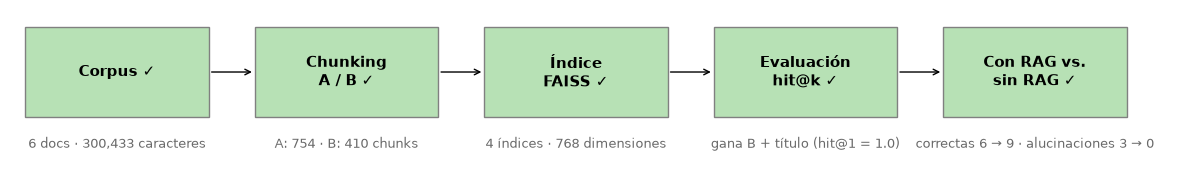

In [34]:
mostrar_progreso("Fin")

### 4. Análisis de errores

#### ¿Cuándo falla el buscador?

Listamos las búsquedas en las que el documento correcto no quedó en el primer puesto:

In [35]:
filas = []
for nombre, (indice, chunks) in INDICES.items():
    for i, p in enumerate(preguntas_eval):
        puesto = PUESTOS[nombre][i]
        if puesto != 1:
            top = buscar(p["pregunta"], 5, indice=indice, chunks=chunks)
            filas.append({"N°": i + 1, "Pregunta": p["pregunta"], "Índice": nombre,
                          "Documento esperado": p["documento_fuente"],
                          "Primer puesto correcto": puesto if puesto else "no aparece",
                          "Documentos del top 5": " | ".join(r["doc_titulo"] for r in top)})
display(pd.DataFrame(filas))

,N°,Pregunta,Índice,Documento esperado,Primer puesto correcto,Documentos del top 5
0,9,¿Dónde nació Ernesto Sábato?,A — Fixed-size,Ernesto Sabato,3,Julio Cortázar | Mario Vargas Llosa | Ernesto Sabato | Ernesto Sabato | Mario Vargas Llosa
1,9,¿Dónde nació Ernesto Sábato?,A + título,Ernesto Sabato,2,Julio Cortázar | Ernesto Sabato | Ernesto Sabato | Ernesto Sabato | Adolfo Bioy Casares
2,3,¿Dónde nació Julio Cortázar?,B — Paragraph-aware,Julio Cortázar,2,Adolfo Bioy Casares | Julio Cortázar | Ernesto Sabato | Julio Cortázar | Jorge Luis Borges
3,4,¿Cuál es la obra más conocida de Julio Cortázar?,B — Paragraph-aware,Julio Cortázar,2,Gabriel García Márquez | Julio Cortázar | Ernesto Sabato | Julio Cortázar | Julio Cortázar


Con B + título, el documento correcto quedó primero en las 10 preguntas. Las otras configuraciones fallan el primer puesto en pocas búsquedas: la pregunta 9 (Sabato) con A y A + título, y las preguntas 3 y 4 (Cortázar) con B. El ejemplo de la sección 9 muestra por qué: ante "¿Dónde nació Julio Cortázar?" el primer chunk fue de Bioy Casares, que también habla de un nacimiento. El modelo capta el tipo de pregunta pero le da poco peso al nombre, y agregar el título resolvió los casos de B.

Una limitación de la métrica: `hit@k` mide si aparece el documento correcto, no si el chunk recuperado contiene la respuesta.

#### ¿Cuándo se equivoca el LLM a pesar del RAG?

Para cada pregunta revisamos si una palabra clave de la respuesta esperada aparece en los 3 chunks que recibió el modelo:

In [36]:
# palabra clave de la respuesta esperada (es un control simple de texto)
CLAVES = ["Buenos Aires", "1899", "Ixelles", "Rayuela", "Nobel",
          "Cien años de soledad", "Perú", "Nobel", "Rojas", "Borges"]
filas = []
for i, p in enumerate(preguntas_eval):
    res = buscar(p["pregunta"], K_CONTEXTO, indice=indice_B_tit, chunks=chunks_B)
    contexto = " ".join(r["texto"] for r in res)
    filas.append({"N°": i + 1, "Pregunta": p["pregunta"], "Palabra clave": CLAVES[i],
                  "¿Clave en el contexto?": CLAVES[i].lower() in contexto.lower(),
                  "Respuesta CON RAG": respuestas_con[i], "Nota CON RAG": notas_con[i]})
display(pd.DataFrame(filas))

,N°,Pregunta,Palabra clave,¿Clave en el contexto?,Respuesta CON RAG,Nota CON RAG
0,1,¿Dónde nació Jorge Luis Borges?,Buenos Aires,True,"Palermo, Argentina.",C
1,2,¿En qué año nació Jorge Luis Borges?,1899,True,1899,C
2,3,¿Dónde nació Julio Cortázar?,Ixelles,True,"Julio Cortázar nació en Ixelles, un municipio al sur de la ciudad de Bruselas, Bélgica.",C
3,4,¿Cuál es la obra más conocida de Julio Cortázar?,Rayuela,True,Rayuela,C
4,5,¿Qué premio recibió Gabriel García Márquez en 1982?,Nobel,True,Medalla de la Legión de Honor de Francia en París.,I
5,6,¿Qué novela escribió Gabriel García Márquez sobre la familia Buendía?,Cien años de soledad,True,Cien años de soledad,C
6,7,¿En qué país nació Mario Vargas Llosa?,Perú,True,Perú,C
7,8,¿Qué premio recibió Mario Vargas Llosa en 2010?,Nobel,True,Nobel de Literatura,C
8,9,¿Dónde nació Ernesto Sábato?,Rojas,True,"Rojas, Buenos Aires",C
9,10,¿Con qué escritor colaboró frecuentemente Adolfo Bioy Casares?,Borges,True,Con Jorge Luis Borges colaboró frecuentemente Adolfo Bioy Casares.,C


En las 10 preguntas la palabra clave estaba en el contexto: el dato que hacía falta siempre le llegó al modelo.

Con RAG no hubo alucinaciones. El único error es la pregunta 5: en el contexto estaba el Nobel, pero también una lista de premios de años cercanos (la Legión de Honor de 1981 y otro de 1982), y el modelo eligió la Legión de Honor. No le faltó el dato ni lo inventó: eligió mal dentro del contexto. La instrucción de responder solo con el contexto evitó que inventara, pero no garantiza que elija el dato que responde la pregunta. Creemos que influye el tamaño del modelo (1.500 millones de parámetros). Con un solo caso no podemos hablar de un patrón.

#### ¿Hay patrones por tipo de pregunta?

In [37]:
TIPOS = ["lugar de nacimiento", "año de nacimiento", "lugar de nacimiento", "obra", "premio",
         "obra", "lugar de nacimiento", "premio", "lugar de nacimiento", "colaboración"]
df_tipo = pd.DataFrame({
    "Tipo": TIPOS,
    "hit@1 A": [p == 1 for p in PUESTOS["A — Fixed-size"]],
    "hit@1 B": [p == 1 for p in PUESTOS["B — Paragraph-aware"]],
    "hit@1 B + título": [p == 1 for p in PUESTOS["B + título"]],
    "SIN RAG correcta": [n == "C" for n in notas_sin],
    "CON RAG correcta": [n == "C" for n in notas_con],
})
tabla_tipo = df_tipo.groupby("Tipo").sum()
tabla_tipo.insert(0, "preguntas", df_tipo.groupby("Tipo").size())
display(tabla_tipo)

,preguntas,hit@1 A,hit@1 B,hit@1 B + título,SIN RAG correcta,CON RAG correcta
Tipo,,,,,,
año de nacimiento,1,1,1,1,1,1
colaboración,1,1,1,1,1,1
lugar de nacimiento,4,3,3,4,1,4
obra,2,2,1,2,1,2
premio,2,2,2,2,2,1


Con 10 preguntas, los patrones son indicios y no conclusiones firmes. Sin RAG, las preguntas de lugar de nacimiento fueron las más difíciles (1 bien de 4) y las de premios las más fáciles (2 de 2): el modelo acierta los datos muy conocidos, como los Nobel, e inventa los más específicos, como dónde nació cada autor. Con RAG, las de lugar de nacimiento pasan a 4 de 4, y el único error es de un premio. En el buscador, los fallos de `hit@1` aparecen en preguntas de lugar de nacimiento y de obras.

### 5. Conclusiones y trabajo futuro

**Qué funcionó**
- *Buscador:* en las 10 preguntas el documento correcto estuvo siempre entre los 3 primeros chunks, en las cuatro configuraciones. B + título fue la única con `hit@1` perfecto.
- *Chunking:* la estrategia por párrafos solo supera a la de tamaño fijo cuando se agrega el título del artículo; sin título queda por debajo. Con título, además, la precisión@5 de B sube de 0,58 a 0,88. Lo que más mejoró la búsqueda fue darle a cada vector el contexto de *quién* habla.
- *RAG:* el modelo pasó de 6 a 9 respuestas correctas sobre 10 y de 3 alucinaciones a ninguna. Corrigió las tres alucinaciones y la respuesta parcial que había sin contexto, y ante una pregunta sin respuesta en el corpus dijo que no tenía información en lugar de inventar.

**Qué fue más difícil**
- El modelo de embeddings le da poco peso a los nombres propios: en la pregunta sobre Cortázar con B, el primer chunk fue de Bioy Casares.
- RAG no siempre mejora: en la pregunta 5 el modelo eligió un premio equivocado de la lista que recibió, cuando sin contexto había respondido bien.

**Limitaciones**
- Son 10 preguntas: cada una pesa 10 puntos, y `hit@3` y `hit@5` quedaron en 1,0 en todas las configuraciones, así que no las distinguen. Además, todas las preguntas nombran al autor, lo que facilita la búsqueda.
- El índice de RAG lo elegimos con las mismas preguntas con las que evaluamos la generación.
- Los prompts con y sin RAG no son idénticos.
- La calificación C/P/I/A es manual y algunos casos, como "Palermo", admiten más de una lectura.
- Probamos un solo modelo de embeddings y un solo LLM, ambos chicos.

#### Trabajo futuro

- **Cortar los chunks en los títulos de sección**, para que un chunk no junte el final de una sección con el principio de la siguiente, y probar tamaños entre 300 y 600 caracteres.
- **Evaluar el buscador a nivel de chunk** (si el chunk recuperado contiene la respuesta), además de a nivel de documento.
- **Ampliar el set de preguntas**, con más tipos y con preguntas que no nombren al autor ("¿quién escribió *Rayuela*?"), para que `hit@3` y `hit@5` distingan entre configuraciones.
- **Mejorar la generación:** probar un modelo más grande, usar el mismo formato de prompt con y sin RAG, y pedirle que cite el fragmento del que saca la respuesta.
- **Probar un reordenamiento (*reranking*)** de los primeros resultados, para los casos en que el nombre del autor pesa poco.

## Referencias

- Notebook de clase `PLN_RAG_pipeline` (Aprendizaje Automático II, Prof. César Martínez): base para la descarga de Wikipedia, el índice FAISS, la búsqueda y la generación con el LLM.
- Artículos de Wikipedia en español de los seis autores, descargados el 27/09/2026.
- Modelo de embeddings: `sentence-transformers/paraphrase-multilingual-mpnet-base-v2` (Hugging Face).
- LLM: `Qwen/Qwen2.5-1.5B-Instruct` (Hugging Face).
- Librerías: `wikipedia`, `sentence-transformers`, `faiss-cpu`, `transformers`, `pandas` y `matplotlib`.